In [ ]:
pip install catboost

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.1/97.1 MB 9.3 MB/s eta 0:00:00


In [ ]:
# Core libraries
import pandas as pd
import numpy as np

# Visualization libraries
import matplotlib.pyplot as plt
import seaborn as sns

# Preprocessesing
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Models
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from lightgbm import LGBMClassifier
from xgboost import XGBClassifier
from catboost import CatBoostClassifier



In [ ]:
train_df = pd.read_csv('/content/train.csv')
test_df = pd.read_csv('/content/test.csv')

In [ ]:
train_df.head()

,id,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,0,Male,0,Yes,Yes,29,Yes,No,DSL,Yes,...,Yes,Yes,No,No,One year,Yes,Mailed check,60.10,1653.85,No
1,1,Male,0,Yes,Yes,58,Yes,No,DSL,Yes,...,No,Yes,Yes,No,Two year,No,Credit card (automatic),69.50,3778.20,No
2,2,Male,0,Yes,No,58,Yes,Yes,Fiber optic,No,...,No,No,Yes,Yes,Month-to-month,Yes,Electronic check,100.40,5841.35,No
3,3,Female,0,No,No,1,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,69.70,70.70,Yes
4,4,Female,0,No,No,1,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.45,70.45,Yes


In [ ]:
test_df.head()

,id,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges
0,594194,Female,0,Yes,No,72,Yes,Yes,Fiber optic,Yes,Yes,Yes,Yes,Yes,Yes,Two year,Yes,Electronic check,115.55,8061.50
1,594195,Female,0,Yes,No,71,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Bank transfer (automatic),19.80,1336.50
2,594196,Male,0,No,No,12,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Bank transfer (automatic),55.55,633.55
3,594197,Male,0,Yes,Yes,71,Yes,Yes,DSL,Yes,No,Yes,Yes,Yes,Yes,Two year,No,Credit card (automatic),84.10,6457.15
4,594198,Female,0,No,No,15,Yes,No,Fiber optic,Yes,No,No,No,Yes,Yes,Month-to-month,No,Electronic check,90.35,1233.65


# **INSPECTION OF DATA**

**1. Shape Of The Data**

In [ ]:
# Shape
train_df.shape, test_df.shape

((7849, 21), (7900, 20))

In [ ]:
# Data info
train_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7849 entries, 0 to 7848
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   id                7849 non-null   int64  
 1   gender            7849 non-null   object 
 2   SeniorCitizen     7849 non-null   int64  
 3   Partner           7849 non-null   object 
 4   Dependents        7849 non-null   object 
 5   tenure            7849 non-null   int64  
 6   PhoneService      7849 non-null   object 
 7   MultipleLines     7849 non-null   object 
 8   InternetService   7849 non-null   object 
 9   OnlineSecurity    7848 non-null   object 
 10  OnlineBackup      7848 non-null   object 
 11  DeviceProtection  7848 non-null   object 
 12  TechSupport       7848 non-null   object 
 13  StreamingTV       7848 non-null   object 
 14  StreamingMovies   7848 non-null   object 
 15  Contract          7848 non-null   object 
 16  PaperlessBilling  7848 non-null   object 


In [ ]:
for col in train_df.select_dtypes(include='object'):
    try:
        pd.to_numeric(train_df[col])
        print(f"{col} can be numeric")
    except:
        print(f"{col} contains non-numeric values")

gender contains non-numeric values
Partner contains non-numeric values
Dependents contains non-numeric values
PhoneService contains non-numeric values
MultipleLines contains non-numeric values
InternetService contains non-numeric values
OnlineSecurity contains non-numeric values
OnlineBackup contains non-numeric values
DeviceProtection contains non-numeric values
TechSupport contains non-numeric values
StreamingTV contains non-numeric values
StreamingMovies contains non-numeric values
Contract contains non-numeric values
PaperlessBilling contains non-numeric values
PaymentMethod contains non-numeric values
Churn contains non-numeric values


In [ ]:
train_df[train_df.isna().any(axis=1)]

,id,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
7848,7848,Male,0,Yes,Yes,59,Yes,No,DSL,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
# Checking for missing values
train_df.isna().sum()

,0
id,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,1


In [ ]:
train_df = train_df.dropna()

In [ ]:
# Checking duplicate
train_df.duplicated().sum()

np.int64(0)

In [ ]:
# Droping the id column
test_ids = test_df['id'] # Store test ids before dropping
train_df.drop('id', axis=1, inplace=True)
test_df.drop('id', axis=1, inplace=True)

In [ ]:
train_df.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Male,0,Yes,Yes,29,Yes,No,DSL,Yes,No,Yes,Yes,No,No,One year,Yes,Mailed check,60.10,1653.85,No
1,Male,0,Yes,Yes,58,Yes,No,DSL,Yes,Yes,No,Yes,Yes,No,Two year,No,Credit card (automatic),69.50,3778.20,No
2,Male,0,Yes,No,58,Yes,Yes,Fiber optic,No,Yes,No,No,Yes,Yes,Month-to-month,Yes,Electronic check,100.40,5841.35,No
3,Female,0,No,No,1,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,69.70,70.70,Yes
4,Female,0,No,No,1,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.45,70.45,Yes


In [ ]:
test_df.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges
0,Female,0,Yes,No,72,Yes,Yes,Fiber optic,Yes,Yes,Yes,Yes,Yes,Yes,Two year,Yes,Electronic check,115.55,8061.50
1,Female,0,Yes,No,71,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Bank transfer (automatic),19.80,1336.50
2,Male,0,No,No,12,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Bank transfer (automatic),55.55,633.55
3,Male,0,Yes,Yes,71,Yes,Yes,DSL,Yes,No,Yes,Yes,Yes,Yes,Two year,No,Credit card (automatic),84.10,6457.15
4,Female,0,No,No,15,Yes,No,Fiber optic,Yes,No,No,No,Yes,Yes,Month-to-month,No,Electronic check,90.35,1233.65


# **EXPLORATORY DATA ANALYSIS**

In [ ]:
# Classifying thetraing data into numeric and categorical
numeric_col = train_df.select_dtypes(include=np.number).columns
categorical_col = train_df.select_dtypes(include='object').columns

In [ ]:
for col in categorical_col:
    print(f"\nColumn: {col}")
    counts = train_df[col].value_counts()
    perc = train_df[col].value_counts(normalize=True) * 100
    df_balance = pd.DataFrame({'Count': counts, 'Percentage': perc})
    display(df_balance)


Column: gender


,Count,Percentage
gender,,
Female,3945,50.267584
Male,3903,49.732416



Column: Partner


,Count,Percentage
Partner,,
No,4044,51.529052
Yes,3804,48.470948



Column: Dependents


,Count,Percentage
Dependents,,
No,5624,71.66157
Yes,2224,28.33843


... (22 outputs left out)


Column: PaymentMethod


,Count,Percentage
PaymentMethod,,
Electronic check,2982,37.996942
Mailed check,1715,21.852701
Credit card (automatic),1658,21.126402
Bank transfer (automatic),1493,19.023955



Column: Churn


,Count,Percentage
Churn,,
No,5834,74.337411
Yes,2014,25.662589


In [ ]:
train_df['Churn_binary'] = train_df['Churn'].apply(lambda x: 1 if x == 'Yes' else 0)

In [ ]:
# Churn rate per category
for col in categorical_col:
    print(f"\n===== {col} =====")
    churn_rate = pd.crosstab(
        train_df[col],
        train_df['Churn_binary'],
        normalize='index'
    )
    display(churn_rate)


===== gender =====


Churn_binary,0,1
gender,,
Female,0.745501,0.254499
Male,0.741225,0.258775



===== Partner =====


Churn_binary,0,1
Partner,,
No,0.630811,0.369189
Yes,0.863039,0.136961



===== Dependents =====


Churn_binary,0,1
Dependents,,
No,0.669986,0.330014
Yes,0.928957,0.071043


... (22 outputs left out)


===== PaymentMethod =====


Churn_binary,0,1
PaymentMethod,,
Bank transfer (automatic),0.926323,0.073677
Credit card (automatic),0.930036,0.069964
Electronic check,0.462106,0.537894
Mailed check,0.892711,0.107289



===== Churn =====


Churn_binary,0,1
Churn,,
No,1.0,0.0
Yes,0.0,1.0


In [ ]:
# Difference between max and min churn rate

for col in categorical_col:
    rates = train_df.groupby(col)['Churn_binary'].mean()
    strength = rates.max() - rates.min()
    print(f"{col}: {strength:.3f}")

gender: 0.004
Partner: 0.232
Dependents: 0.259
PhoneService: 0.052
MultipleLines: 0.094
InternetService: 0.437
OnlineSecurity: 0.430
OnlineBackup: 0.430
DeviceProtection: 0.421
TechSupport: 0.430
StreamingTV: 0.341
StreamingMovies: 0.351
Contract: 0.446
PaperlessBilling: 0.266
PaymentMethod: 0.468
Churn: 1.000


In [ ]:
# Chi-Square test
from scipy.stats import chi2_contingency

for col in categorical_col:
    table = pd.crosstab(train_df[col], train_df['Churn_binary'])
    chi2, p, _, _ = chi2_contingency(table)
    print(f"{col}: p-value={p}")

gender: p-value=0.6834305697562848
Partner: p-value=2.9226282177124647e-122
Dependents: p-value=1.4317794000393288e-123
PhoneService: p-value=0.015128998115414315
MultipleLines: p-value=1.4929121052730167e-14
InternetService: p-value=0.0
OnlineSecurity: p-value=0.0
OnlineBackup: p-value=2.3030837429224292e-287
DeviceProtection: p-value=3.469020967964539e-266
TechSupport: p-value=0.0
StreamingTV: p-value=8.379381253003451e-167
StreamingMovies: p-value=1.5763831302013779e-170
Contract: p-value=0.0
PaperlessBilling: p-value=3.5007729543233587e-149
PaymentMethod: p-value=0.0
Churn: p-value=0.0


**Numeric Variables analysis**

In [ ]:
numeric_col

Index(['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges'], dtype='object')

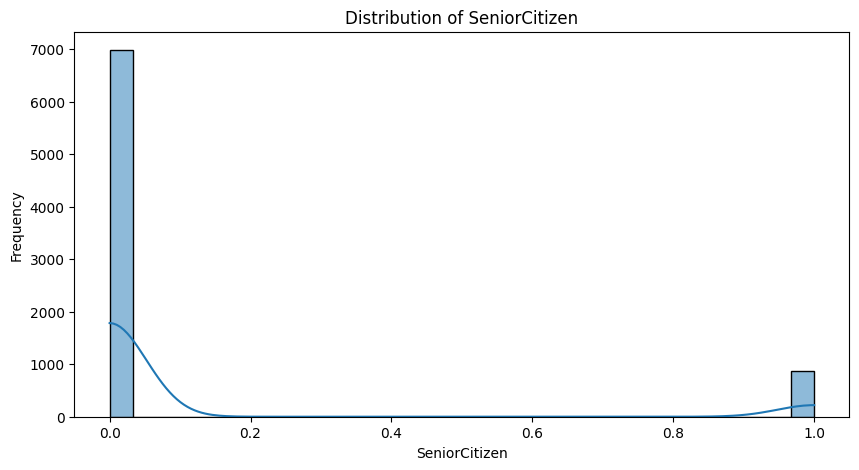

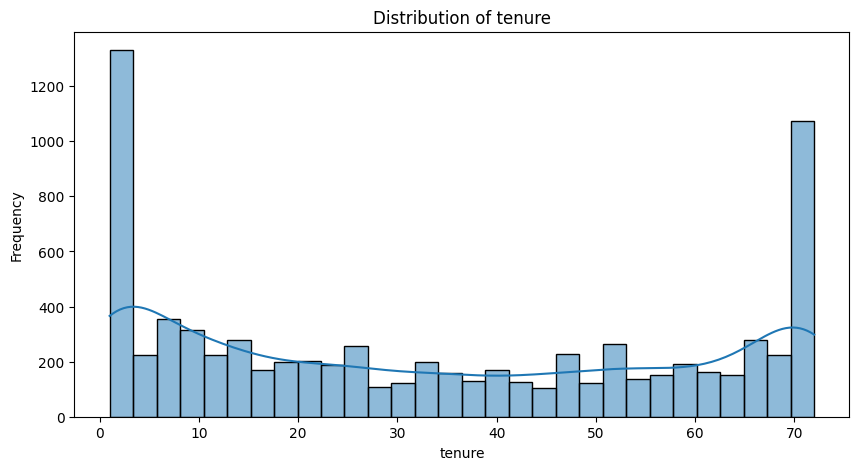

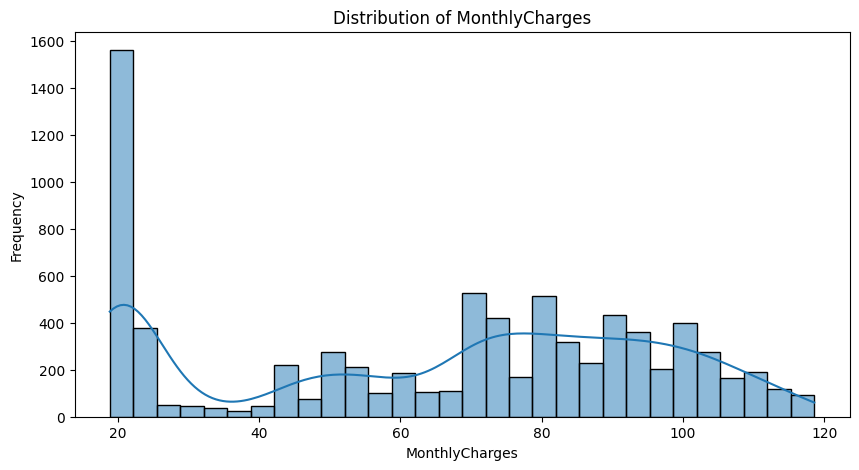

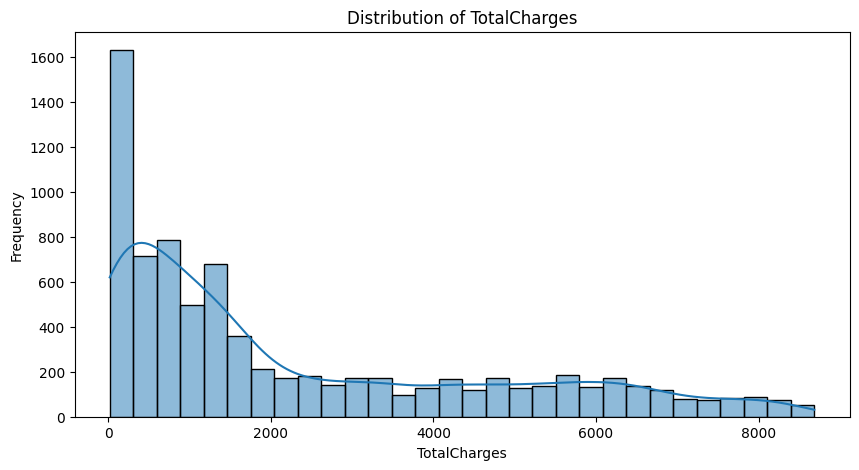

In [ ]:
# Checking on the distribution of the columns

for col in numeric_col:
    plt.figure(figsize=(10, 5))
    sns.histplot(train_df[col],bins = 30,kde=True)
    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Frequency")
    plt.show()

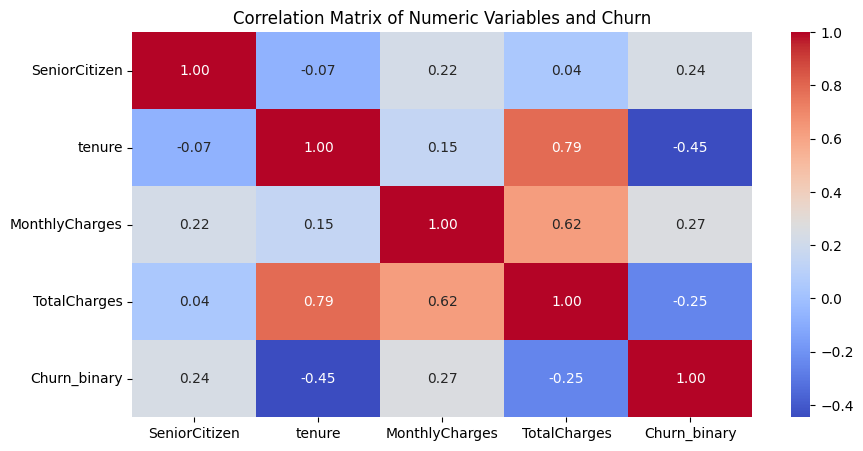

In [ ]:
all_numeric_and_churn = list(numeric_col) + ['Churn_binary']
plt.figure(figsize=(10, 5))
sns.heatmap(train_df[all_numeric_and_churn].corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title("Correlation Matrix of Numeric Variables and Churn")
plt.show()

In [ ]:
train_df.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,...,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn,Churn_binary
0,Male,0,Yes,Yes,29,Yes,No,DSL,Yes,No,...,Yes,No,No,One year,Yes,Mailed check,60.10,1653.85,No,0
1,Male,0,Yes,Yes,58,Yes,No,DSL,Yes,Yes,...,Yes,Yes,No,Two year,No,Credit card (automatic),69.50,3778.20,No,0
2,Male,0,Yes,No,58,Yes,Yes,Fiber optic,No,Yes,...,No,Yes,Yes,Month-to-month,Yes,Electronic check,100.40,5841.35,No,0
3,Female,0,No,No,1,Yes,No,Fiber optic,No,No,...,No,No,No,Month-to-month,Yes,Electronic check,69.70,70.70,Yes,1
4,Female,0,No,No,1,Yes,No,Fiber optic,No,No,...,No,No,No,Month-to-month,Yes,Electronic check,70.45,70.45,Yes,1


# **DATA PREPROCESSESING**

In [ ]:
X = train_df.drop(['Churn', 'Churn_binary','PaymentMethod'], axis=1)
y = train_df['Churn_binary']

**2. Identify Column Types**

In [ ]:
nume_col = X.select_dtypes(include=np.number).columns
cate_col = X.select_dtypes(include='object').columns

**3. Build Transformers**


In [ ]:
# Numeric pipeline
numeric_transformer = Pipeline(steps=[
    ('scaler', StandardScaler())
])


In [ ]:
# Categorical Pipeline

categorical_transformer = Pipeline(steps=[
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])


**4. Combine Pipelines**

In [ ]:
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, nume_col),
        ('cat',categorical_transformer,cate_col)
    ])

**5. Attach the Model**

In [ ]:
models = {

"LightGBM": LGBMClassifier(
    n_estimators=500,
    learning_rate=0.05,
    random_state=42
),

"XGBoost": XGBClassifier(
    n_estimators=500,
    learning_rate=0.05,
    max_depth=6,
    random_state=42,
    eval_metric="logloss"
),

"CatBoost": CatBoostClassifier(
    iterations=500,
    learning_rate=0.05,
    depth=6,
    verbose=0
)

}

**2. Use Cross Validation**

In [ ]:
import warnings
warnings.filterwarnings("ignore", category=UserWarning)

In [ ]:
from sklearn.model_selection import cross_val_score,RandomizedSearchCV
import pandas as pd

results = []

for name, model in models.items():

    pipe = Pipeline([
        ("preprocess", preprocessor),
        ("model", model)
    ])

    scores = cross_val_score(pipe, X, y,
                             cv=5,
                             scoring="accuracy")

    results.append({
        "model": name,
        "mean_score": scores.mean(),
        "std": scores.std()
    })

results_df = pd.DataFrame(results).sort_values("mean_score", ascending=False)

print(results_df)

[LightGBM] [Info] Number of positive: 1611, number of negative: 4667
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.004742 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 660
[LightGBM] [Info] Number of data points in the train set: 6278, number of used features: 41
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.256610 -> initscore=-1.063661
[LightGBM] [Info] Start training from score -1.063661
[LightGBM] [Info] Number of positive: 1611, number of negative: 4667
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.001297 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 660
[LightGBM] [Info] Number of data points in the train set: 6278, number of used features: 41
[LightGBM] [Info] [binary:

# Tune CatBoost

In [ ]:
cat_model = CatBoostClassifier(verbose=0,random_state=42)

para_grid = {
    "model__depth": [4, 6, 8,10],
    "model__learning_rate": [0.01,0.03, 0.05,0.1],
    "model__iterations": [300, 500, 800],
    "model__l2_leaf_reg": [1, 3, 5, 7, 9]
}

pipe = Pipeline([
    ("preprocess", preprocessor),
    ("model", cat_model)
])

search = RandomizedSearchCV(
    pipe,
    para_grid,
    n_iter=20,
    cv=3,
    scoring="accuracy",
    n_jobs=-1
)

search.fit(X, y)

best_cat = search.best_estimator_

print(search.best_params_)

{'model__learning_rate': 0.05, 'model__l2_leaf_reg': 1, 'model__iterations': 300, 'model__depth': 4}


### Tune XGBoost

In [ ]:
xgb_model_tune = XGBClassifier(random_state=42, use_label_encoder=False, eval_metric='logloss', n_jobs=-1)

para_grid_xgb = {
    "model__n_estimators": [300, 500, 800, 1000],
    "model__learning_rate": [0.01, 0.05, 0.1, 0.2],
    "model__max_depth": [3, 6, 9, 12],
    "model__subsample": [0.7, 0.8, 0.9, 1.0],
    "model__colsample_bytree": [0.7, 0.8, 0.9, 1.0],
    "model__gamma": [0, 0.1, 0.2, 0.3],
    "model__lambda": [0, 0.1, 0.5, 1, 2],
    "model__alpha": [0, 0.1, 0.5, 1, 2]
}

pipe_xgb_tune = Pipeline([
    ("preprocess", preprocessor),
    ("model", xgb_model_tune)
])

search_xgb = RandomizedSearchCV(
    pipe_xgb_tune,
    para_grid_xgb,
    n_iter=50, # Increased iterations for a more thorough search
    cv=3,
    scoring="roc_auc", # Optimize for ROC AUC directly
    n_jobs=-1,
    verbose=1
)

print("Starting XGBoost hyperparameter tuning...")
search_xgb.fit(X, y)

best_xgb = search_xgb.best_estimator_

print("Finished XGBoost hyperparameter tuning.")
print(f"Best XGBoost parameters: {search_xgb.best_params_}")
print(f"Best XGBoost ROC AUC score: {search_xgb.best_score_}")

Starting XGBoost hyperparameter tuning...
Fitting 3 folds for each of 50 candidates, totalling 150 fits
Finished XGBoost hyperparameter tuning.
Best XGBoost parameters: {'model__subsample': 0.7, 'model__n_estimators': 1000, 'model__max_depth': 3, 'model__learning_rate': 0.01, 'model__lambda': 0.5, 'model__gamma': 0.3, 'model__colsample_bytree': 1.0, 'model__alpha': 0}
Best XGBoost ROC AUC score: 0.9106918714528337


After tuning XGBoost, we can try blending `best_cat` (tuned CatBoost), `best_lgb` (tuned LightGBM), and the newly tuned `best_xgb` to see if we can achieve a higher AUC. We should also consider optimizing the blending weights for these three models.

### Resolving `NameError: name 'best_lgb' is not defined`

The error occurred because the LightGBM model (`best_lgb`) was used in cell `3c3efe9d` before it was defined. The cell that tunes LightGBM and defines `best_lgb` is located at `f41ae65c`.

**To resolve this error, please follow these steps:**
1. Run the cell with ID `f41ae65c` (titled `Tune LightGBM`). This will train and define the `best_lgb` model.
2. Once cell `f41ae65c` has completed execution, re-run the ensemble blending cell with ID `3c3efe9d`.

# Train LightGBM

In [ ]:
from lightgbm import LGBMClassifier

lgb_model = LGBMClassifier(
    n_estimators=800,
    learning_rate=0.03,
    max_depth=-1,
    num_leaves=31,
    random_state=42
)

pipe = Pipeline([
    ("preprocess", preprocessor),
    ("model", lgb_model)
])

pipe.fit(X, y)

[LightGBM] [Info] Number of positive: 2014, number of negative: 5834
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.001205 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 660
[LightGBM] [Info] Number of data points in the train set: 7848, number of used features: 41
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.256626 -> initscore=-1.063580
[LightGBM] [Info] Start training from score -1.063580


Pipeline(steps=[('preprocess',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('scaler',
                                                                   StandardScaler())]),
                                                  Index(['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges'], dtype='object')),
                                                 ('cat',
                                                  Pipeline(steps=[('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  Index(['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines',
       'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
       'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract',
       'PaperlessBilling'],
      dtype='object'))])),
                ('model',
                 LGBMClassifier(learning_rate=0.03, n_estimators=800,
                                random_state=42))])

# Train CatBoost with Best Parameters

In [ ]:
best_cat.fit(X, y)

Pipeline(steps=[('preprocess',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('scaler',
                                                                   StandardScaler())]),
                                                  Index(['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges'], dtype='object')),
                                                 ('cat',
                                                  Pipeline(steps=[('onehot',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  Index(['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines',
       'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
       'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract',
       'PaperlessBilling'],
      dtype='object'))])),
                ('model',
                 CatBoostClassifier(depth=4, iterations=300, l2_leaf_reg=1, learning_rate=0.05, random_state=42, verbose=0))])

In [ ]:
cat_pred = best_cat.predict_proba(test_df)[:,1]
lgb_pred = pipe.predict_proba(test_df)[:,1]

In [ ]:
final_pred = 0.6 * cat_pred + 0.4 * lgb_pred

In [ ]:
final_pred

array([1.12241900e-02, 1.17473704e-04, 1.46403150e-01, ...,
       6.75557376e-01, 8.44180280e-01, 1.30188513e-03])

In [ ]:
submission = pd.DataFrame({
    "id": test_ids,
    "Churn": final_pred
})


In [ ]:
submission.head()

,id,Churn
0,594194,0.011224
1,594195,0.000117
2,594196,0.146403
3,594197,0.003103
4,594198,0.428277


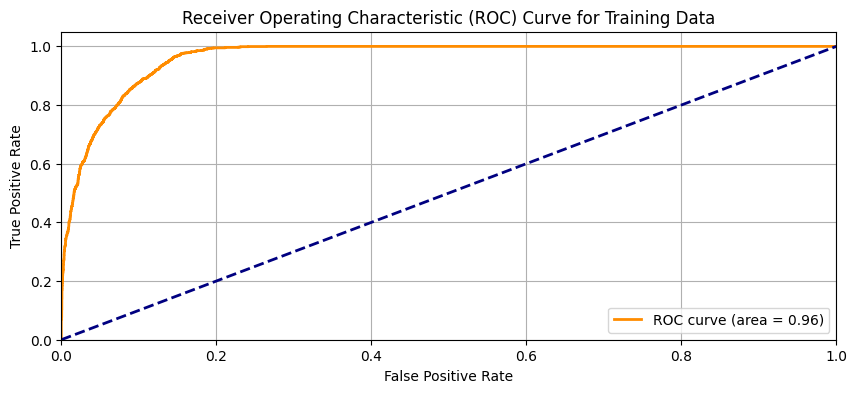

In [ ]:
# Generate predictions on the training data for ROC AUC calculation
cat_pred_train = best_cat.predict_proba(X)[:,1]
lgb_pred_train = pipe.predict_proba(X)[:,1]
final_pred_train = 0.6 * cat_pred_train + 0.4 * lgb_pred_train

from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

# Calculate ROC curve for training data
fpr, tpr, thresholds = roc_curve(y, final_pred_train)
roc_auc = auc(fpr, tpr)

# Plot ROC curve
plt.figure(figsize=(10, 4))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (area = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve for Training Data')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()


In [ ]:

print(f"The Area Under the Curve (AUC) for the training data is: {roc_auc:.4f}")

The Area Under the Curve (AUC) for the training data is: 0.9627


In [ ]:
lgb_model_tune = LGBMClassifier(random_state=42, n_jobs=-1) # Use n_jobs=-1 for parallel processing

para_grid_lgb = {
    "model__n_estimators": [300, 500, 800],
    "model__learning_rate": [0.01, 0.05, 0.1],
    "model__num_leaves": [20, 31, 40],
    "model__max_depth": [-1, 6, 10],
    "model__subsample": [0.8, 1.0],
    "model__colsample_bytree": [0.8, 1.0],
    "model__reg_alpha": [0, 0.1, 0.3],
    "model__reg_lambda": [0, 0.1, 0.3],
}

pipe_lgb_tune = Pipeline([
    ("preprocess", preprocessor),
    ("model", lgb_model_tune)
])

search_lgb = RandomizedSearchCV(
    pipe_lgb_tune,
    para_grid_lgb,
    n_iter=30, # Increased iterations for a more thorough search
    cv=3,
    scoring="roc_auc", # Optimize for ROC AUC directly
    n_jobs=-1,
    verbose=1
)

print("Starting LightGBM hyperparameter tuning...")
search_lgb.fit(X, y)

best_lgb = search_lgb.best_estimator_

print("Finished LightGBM hyperparameter tuning.")
print(f"Best LightGBM parameters: {search_lgb.best_params_}")
print(f"Best LightGBM ROC AUC score: {search_lgb.best_score_}")


Starting LightGBM hyperparameter tuning...
Fitting 3 folds for each of 30 candidates, totalling 90 fits
[LightGBM] [Info] Number of positive: 2014, number of negative: 5834
[LightGBM] [Info] Auto-choosing row-wise multi-threading, the overhead of testing was 0.001128 seconds.
You can set `force_row_wise=true` to remove the overhead.
And if memory is not enough, you can set `force_col_wise=true`.
[LightGBM] [Info] Total Bins 660
[LightGBM] [Info] Number of data points in the train set: 7848, number of used features: 41
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.256626 -> initscore=-1.063580
[LightGBM] [Info] Start training from score -1.063580
Finished LightGBM hyperparameter tuning.
Best LightGBM parameters: {'model__subsample': 1.0, 'model__reg_lambda': 0.1, 'model__reg_alpha': 0.3, 'model__num_leaves': 20, 'model__n_estimators': 300, 'model__max_depth': 6, 'model__learning_rate': 0.01, 'model__colsample_bytree': 0.8}
Best LightGBM ROC AUC score: 0.9081136981356845


After tuning LightGBM, we can retrain both `CatBoost` and the tuned `LightGBM` models with their best parameters and re-evaluate the blended prediction's AUC. If the best `LightGBM` parameters include `scale_pos_weight` > 1, it means the model benefited from handling class imbalance.

Making predictions with tuned LightGBM and CatBoost models...


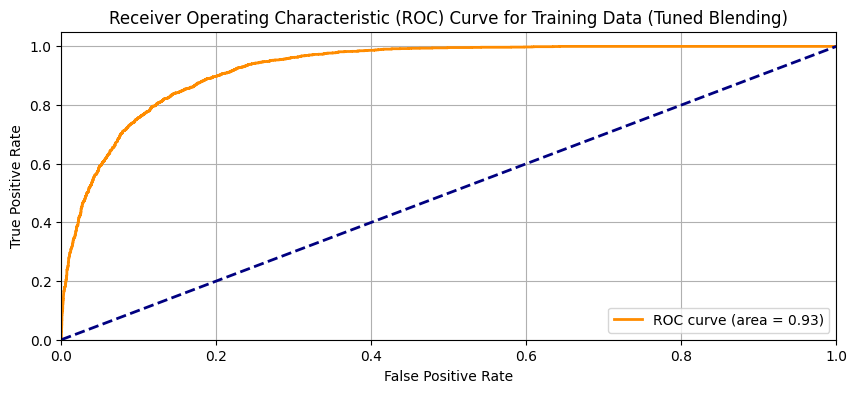

The Area Under the Curve (AUC) for the training data after tuning and blending is: 0.9284
New submission file 'submission_tuned.csv' created.


In [ ]:
# Assuming 'best_lgb' is the tuned LightGBM pipeline from the previous step
# We will use the 'best_lgb' and 'best_cat' models for predictions

print("Making predictions with tuned LightGBM and CatBoost models...")
lgb_pred_tuned = best_lgb.predict_proba(test_df)[:, 1]
cat_pred_tuned = best_cat.predict_proba(test_df)[:, 1]

# Re-evaluate the blended prediction with the tuned models
final_pred_tuned = 0.6 * cat_pred_tuned + 0.4 * lgb_pred_tuned

# Generate predictions on the training data for ROC AUC calculation with tuned models
cat_pred_train_tuned = best_cat.predict_proba(X)[:,1]
lgb_pred_train_tuned = best_lgb.predict_proba(X)[:,1]
final_pred_train_tuned = 0.6 * cat_pred_train_tuned + 0.4 * lgb_pred_train_tuned

from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

# Calculate ROC curve for training data with tuned models
fpr_tuned, tpr_tuned, thresholds_tuned = roc_curve(y, final_pred_train_tuned)
roc_auc_tuned = auc(fpr_tuned, tpr_tuned)

# Plot ROC curve
plt.figure(figsize=(10, 4))
plt.plot(fpr_tuned, tpr_tuned, color='darkorange', lw=2, label=f'ROC curve (area = {roc_auc_tuned:.2f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve for Training Data (Tuned Blending)')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()

print(f"The Area Under the Curve (AUC) for the training data after tuning and blending is: {roc_auc_tuned:.4f}")

submission_tuned = pd.DataFrame({
    "id": test_ids,
    "Churn": final_pred_tuned
})

submission_tuned["Churn"] = submission_tuned["Churn"].round(2)
submission_tuned.to_csv("submission_tuned.csv", index=False)

print("New submission file 'submission_tuned.csv' created.")


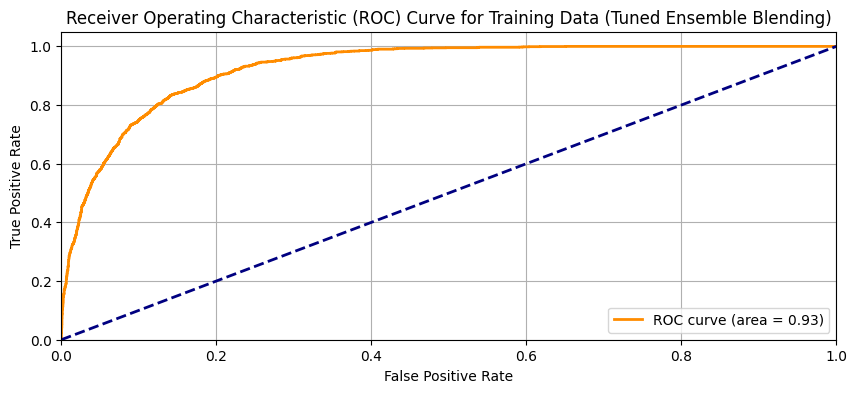

The Area Under the Curve (AUC) for the training data after tuning and ensemble blending is: 0.9270
New submission file 'submission_ensemble.csv' created.


In [ ]:
# Predict probabilities on the test set using the tuned models
cat_pred_tuned = best_cat.predict_proba(test_df)[:, 1]
lgb_pred_tuned = best_lgb.predict_proba(test_df)[:, 1]
xgb_pred_tuned = best_xgb.predict_proba(test_df)[:, 1]

# Let's try an equal weight blend for now or define custom weights
# You can experiment with different weights based on individual model performance or validation scores
# For example, if XGBoost is the strongest, give it more weight

# Example of weighted blend (you can adjust these weights)
# For instance, if all models performed similarly, an equal weight could be a good starting point
# Or, if one model has a significantly higher validation AUC, give it more weight.

# For simplicity, let's try a blend that gives slightly more weight to the newly tuned XGBoost
# as it initially had the highest cross-validation score among the original models.
# Weights sum to 1: CatBoost (0.3) + LightGBM (0.3) + XGBoost (0.4)
final_pred_ensemble = (0.3 * cat_pred_tuned + 0.3 * lgb_pred_tuned + 0.4 * xgb_pred_tuned)

# Evaluate the blended prediction on the training data for ROC AUC calculation
cat_pred_train_tuned = best_cat.predict_proba(X)[:,1]
lgb_pred_train_tuned = best_lgb.predict_proba(X)[:,1]
xgb_pred_train_tuned = best_xgb.predict_proba(X)[:,1]

final_pred_train_ensemble = (0.3 * cat_pred_train_tuned + 0.3 * lgb_pred_train_tuned + 0.4 * xgb_pred_train_tuned)

from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

# Calculate ROC curve for training data with the ensemble
fpr_ensemble, tpr_ensemble, thresholds_ensemble = roc_curve(y, final_pred_train_ensemble)
roc_auc_ensemble = auc(fpr_ensemble, tpr_ensemble)

# Plot ROC curve
plt.figure(figsize=(10, 4))
plt.plot(fpr_ensemble, tpr_ensemble, color='darkorange', lw=2, label=f'ROC curve (area = {roc_auc_ensemble:.2f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve for Training Data (Tuned Ensemble Blending)')
plt.legend(loc='lower right')
plt.grid(True)
plt.show()

print(f"The Area Under the Curve (AUC) for the training data after tuning and ensemble blending is: {roc_auc_ensemble:.4f}")

# Create a new submission file with the ensemble predictions
submission_ensemble = pd.DataFrame({
    "id": test_ids,
    "Churn": final_pred_ensemble
})

submission_ensemble["Churn"] = submission_ensemble["Churn"].round(2)
submission_ensemble.to_csv("submission_ensemble.csv", index=False)

print("New submission file 'submission_ensemble.csv' created.")

In [ ]:
submission.to_csv("submission.csv", index=False)

In [ ]:
submission["Churn"] = submission["Churn"].round(2)

submission.to_csv("submission_file.csv", index=False)

In [ ]:
submission.head()

,id,Churn
0,594194,0.01
1,594195,0.00
2,594196,0.15
3,594197,0.00
4,594198,0.43
